# Quantising a policy until it breaks

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/5_practice/03_quantisation.ipynb) &nbsp; Guide note: [guide-deployment](https://www.matthewwnuk.com/guide-deployment.html#quantmath)

Quantisation stores weights in fewer bits. The question that matters for a robot is not how much the
outputs move but whether the task still succeeds. This notebook quantises a small trained policy from
16 bits down to 2 and measures both.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import copy, numpy as np, matplotlib.pyplot as plt
from guide_utils import toy, style
style.use(); starts, targets = toy.test_set(300)
X, Y = toy.demonstrations(np.random.default_rng(0), 200, "relative"); policy = toy.Policy().fit(X, Y)
print(f"full-precision policy: {toy.rollout(policy, starts, targets):.0%} success, {sum(w.size for w in policy.net.coefs_ + policy.net.intercepts_):,} weights")

full-precision policy: 97% success, 4,610 weights


## Uniform quantisation

Pick a scale so that the largest weight maps to the largest integer, round every weight to the nearest
level, and scale back. The rounding error is at most half a step.

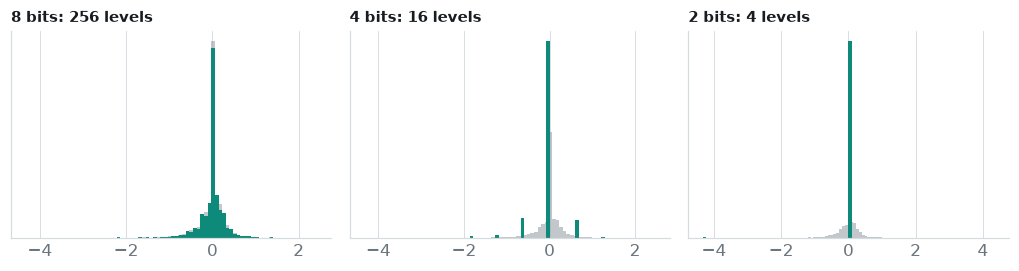

8 bits: mean weight error 0.0054  (weights range over +/-4.33)
4 bits: mean weight error 0.0945  (weights range over +/-4.33)
2 bits: mean weight error 0.1786  (weights range over +/-4.33)


In [3]:
def quantise(w, bits):
    scale = np.abs(w).max() / (2 ** (bits - 1) - 1); return np.round(w / scale) * scale
w = policy.net.coefs_[1]; fig, ax = plt.subplots(1, 3, figsize=(9.4, 2.6))
for a, b in zip(ax, (8, 4, 2)): a.hist(w.ravel(), 80, color=style.GREY, alpha=0.6); a.hist(quantise(w, b).ravel(), 80, color=style.TEAL); a.set_title(f"{b} bits: {2 ** b} levels", fontsize=10); a.set_yticks([])
plt.tight_layout(); plt.show()
for b in (8, 4, 2): print(f"{b} bits: mean weight error {np.abs(quantise(w, b) - w).mean():.4f}  (weights range over +/-{np.abs(w).max():.2f})")

## What it does to the outputs, and to the task

 2 bits: action changes by 508.96% of a step   success 0%
 3 bits: action changes by 143.40% of a step   success 5%
 4 bits: action changes by 118.59% of a step   success 3%
 5 bits: action changes by  57.20% of a step   success 65%
 6 bits: action changes by  27.34% of a step   success 91%
 8 bits: action changes by   7.80% of a step   success 97%
16 bits: action changes by   0.03% of a step   success 97%


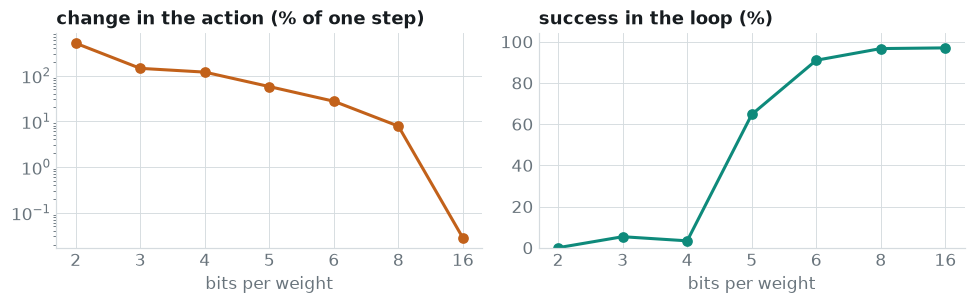

In [4]:
def quantised_policy(bits):
    q = copy.deepcopy(policy)
    for W in q.net.coefs_ + q.net.intercepts_: W[...] = quantise(W, bits)
    return q
bits = [2, 3, 4, 5, 6, 8, 16]; ref = policy.predict(X); err, succ = [], []
for b in bits:
    q = quantised_policy(b); err.append(np.linalg.norm(q.predict(X) - ref, axis=1).mean() / toy.STEP * 100); succ.append(toy.rollout(q, starts, targets) * 100)
    print(f"{b:2d} bits: action changes by {err[-1]:6.2f}% of a step   success {succ[-1]:.0f}%")
fig, ax = plt.subplots(1, 2, figsize=(9, 2.9)); x = range(len(bits))
ax[0].plot(x, err, marker="o", color=style.ORANGE); ax[0].set_yscale("log"); ax[0].set_title("change in the action (% of one step)"); ax[1].plot(x, succ, marker="o"); ax[1].set_ylim(0, 104); ax[1].set_title("success in the loop (%)")
for a in ax: a.set_xticks(x); a.set_xticklabels(bits); a.set_xlabel("bits per weight")
plt.tight_layout(); plt.show()

The action error rises smoothly. Success does not: it holds, and then falls off a cliff. The error on
recorded data does not say where the cliff is. Only running the policy does.

## An outlier makes everything coarser

The scale is set by the largest weight. One unusually large value stretches the range and makes every
other weight's step bigger. Setting the range from a percentile, and clipping what lies beyond it, keeps
the step small for everything else.

In [5]:
def quantise_clipped(w, bits, pct=99.9):
    top = np.percentile(np.abs(w), pct); levels = 2 ** (bits - 1) - 1; scale = top / levels; return np.clip(np.round(w / scale), -levels, levels) * scale
w_out = w.copy(); w_out[0, 0] = 12 * np.abs(w).max(); rest = np.ones(w.shape, bool); rest[0, 0] = False                 # one weight twelve times larger than any other
for b in (8, 6):
    e_max = np.abs(quantise(w_out, b) - w_out)[rest].mean(); e_pct = np.abs(quantise_clipped(w_out, b) - w_out)[rest].mean(); e_clean = np.abs(quantise(w, b) - w)[rest].mean()
    print(f"{b} bits, error on the other weights:  no outlier {e_clean:.4f}   range from the maximum {e_max:.4f}   range from the 99.9th percentile {e_pct:.4f}")

8 bits, error on the other weights:  no outlier 0.0054   range from the maximum 0.0671   range from the 99.9th percentile 0.0044
6 bits, error on the other weights:  no outlier 0.0227   range from the maximum 0.1519   range from the 99.9th percentile 0.0169


With the range set by the outlier, every other weight is rounded about twelve times more coarsely.
The percentile rule gives that precision back, at the price of clipping the one large value. Whether
clipping it is acceptable depends on what that weight does, which is why ranges are chosen with
calibration data and checked by running the model.


## Things to try

- Give each output unit of a layer its own scale (per-channel quantisation). How many bits does that save?
- Quantise only the first layer, or only the last. Which is more sensitive?
- Fine-tune for a few steps after quantising, rounding the weights again after each step.